# Ant Colony Optimization

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(7)
n_cities = 20
city_names = list("ABCDEFGHIJKLMNOPQRST")
coords = rng.integers(0, 100, size=(n_cities, 2))
distance = np.linalg.norm(coords[:, None] - coords[None, :], axis=2)
eta = np.zeros_like(distance)
np.divide(1.0, distance, out=eta, where=distance > 0)

n_ants = 20
n_iterations = 100
alpha = 1
beta = 2
rho = 0.5
Q = 100

In [3]:
def tour_length(tour):
    return sum(distance[tour[i], tour[(i + 1) % n_cities]] for i in range(n_cities))

def build_tour(pheromone, alpha, beta, gen):
    start = gen.integers(n_cities)
    tour = [start]
    unvisited = [c for c in range(n_cities) if c != start]
    while unvisited:
        cur = tour[-1]
        weights = pheromone[cur, unvisited]**alpha * eta[cur, unvisited]**beta
        nxt = gen.choice(unvisited, p=weights / weights.sum())
        tour.append(nxt)
        unvisited.remove(nxt)
    return tour

In [4]:
def aco(n_ants, n_iterations, alpha, beta, rho, Q, seed=42):
    gen = np.random.default_rng(seed)
    pheromone = np.ones((n_cities, n_cities))
    best_tour, best_len = None, np.inf
    history = []
    for _ in range(n_iterations):
        tours = [build_tour(pheromone, alpha, beta, gen) for _ in range(n_ants)]
        lengths = [tour_length(t) for t in tours]
        pheromone *= (1 - rho)
        for t, L in zip(tours, lengths):
            for i in range(n_cities):
                a, b = t[i], t[(i + 1) % n_cities]
                pheromone[a, b] += Q / L
                pheromone[b, a] += Q / L
        k = int(np.argmin(lengths))
        if lengths[k] < best_len:
            best_tour, best_len = tours[k], lengths[k]
        history.append(best_len)
    return best_tour, best_len, history

In [5]:
best_tour, best_len, history = aco(n_ants, n_iterations, alpha, beta, rho, Q)

print("Best Tour   :", " -> ".join(city_names[i] for i in best_tour + [best_tour[0]]))
print(f"Best Length : {best_len:.3f}")

Best Tour   : L -> E -> J -> I -> F -> T -> Q -> H -> C -> B -> R -> A -> N -> K -> D -> G -> M -> S -> P -> O -> L
Best Length : 399.815


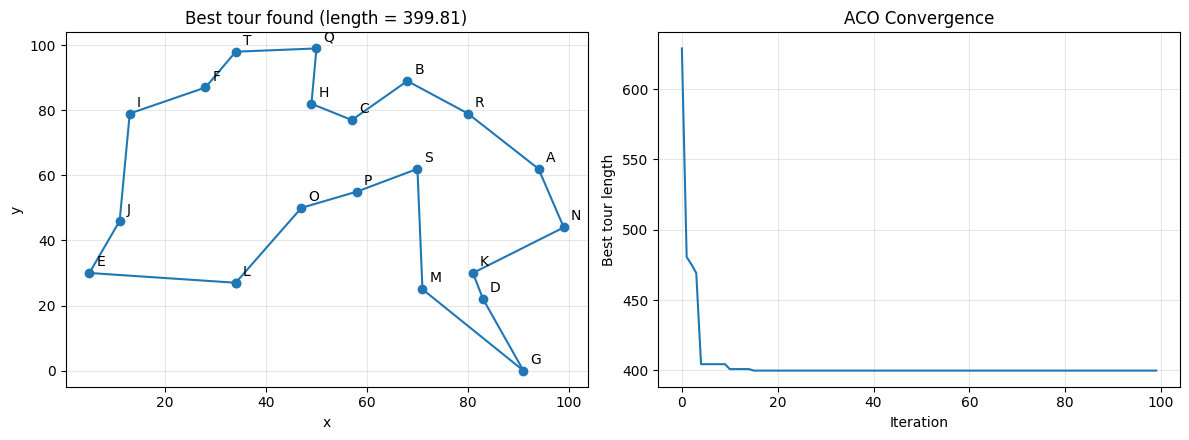

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

closed = best_tour + [best_tour[0]]
ax[0].plot(coords[closed, 0], coords[closed, 1], "o-")
for i, name in enumerate(city_names):
    ax[0].annotate(name, coords[i], xytext=(5, 5), textcoords="offset points")
ax[0].set_title(f"Best tour found (length = {best_len:.2f})")
ax[0].set_xlabel("x")
ax[0].set_ylabel("y")

ax[1].plot(history)
ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Best tour length")
ax[1].set_title("ACO Convergence")

for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
settings = [
    ("Pheromone Influence alpha", "1", "3", dict(alpha=3)),
    ("Distance Influence beta", "2", "5", dict(beta=5)),
    ("Evaporation Rate rho", "0.50", "0.10", dict(rho=0.1)),
    ("Deposit Constant Q", "100", "10", dict(Q=10)),
]
base = dict(n_ants=n_ants, n_iterations=n_iterations, alpha=alpha, beta=beta, rho=rho, Q=Q)
rows = []
for name, old, new, change in settings:
    _, L, _ = aco(**{**base, **change})
    rows.append([name, old, new, f"{best_len:.3f}", f"{L:.3f}"])
table = pd.DataFrame(rows, columns=["Parameter", "Original", "Modified", "Original Best Length", "Modified Best Length"])
table

,Parameter,Original,Modified,Original Best Length,Modified Best Length
0,Pheromone Influence alpha,1,3,399.815,407.517
1,Distance Influence beta,2,5,399.815,399.815
2,Evaporation Rate rho,0.50,0.10,399.815,399.815
3,Deposit Constant Q,100,10,399.815,399.815
